In [1]:
# ===== Setup: libraries and settings =====
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # hide a harmless pandas warning

import pandas as pd
import wrds

conn = wrds.Connection()    # log in to WRDS (type your username and password if asked)

# Settings. If you want to change something, change it here only.
SIC        = "35"            # 2-digit industry we study (Transportation Equipment)
FY_START   = "2021-01-01"     # we study fiscal years that END between FY_START and FY_END
FY_END     = "2024-12-31"
PULL_START = "2019-06-01"     # we pull earlier years too, because the EPS change needs last year's EPS and price
RET_START  = "2020-12-01"     # first month of returns (12 months before the first fiscal year-end)
RET_END    = "2025-01-31"     # last month of returns
MIN_PRC    = 5                # rule: drop a company-year if last year's price is below this
MAX_CHG    = 1                # rule: drop a company-year if the EPS change is bigger than this (up or down)

Loading library list...
Done


In [2]:
# ===== Step 1. Read the link file =====

# 1a. Read every column as text, so that nothing is changed or guessed at this point.
link_all = pd.read_csv("ccm_link.csv", dtype=str)

# 1b. gvkey must have 6 characters (for example 001690). Excel can drop the leading zeros, so we put them back.
link_all["gvkey"] = link_all["gvkey"].str.zfill(6)

# 1c. permno is a number.
link_all["permno"] = pd.to_numeric(link_all["permno"]).astype(int)

# 1d. The two date columns are text. Turn them into real dates, so that we can compare them with other dates.
# format="mixed" accepts different date formats. errors="coerce" turns a bad value into a missing date.
link_all["linkdt"]    = pd.to_datetime(link_all["linkdt"], format="mixed", errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], format="mixed", errors="coerce")

# 1e. A link with no end date is still valid, so we give it a far-future end date.
link_all["linkenddt"] = link_all["linkenddt"].fillna(pd.Timestamp("2099-12-31"))

# 1f. Keep only the companies in our industry.
link = link_all[link_all["sic2"] == SIC].reset_index(drop=True)
if len(link) == 0:
    raise ValueError("SIC " + SIC + " is not in ccm_link.csv. Industries in the file: " + str(sorted(link_all["sic2"].unique())))

print("link rows:", len(link), "| companies:", link["gvkey"].nunique())
link.head()

link rows: 170 | companies: 143


,gvkey,permno,linkdt,linkenddt,sic2,ticker,comnam
0,001050,11499,1980-11-28,2099-12-31,35,CECO,C E C O ENVIRONMENTAL CORP
1,001613,18075,1960-01-01,1965-12-30,35,AP,AMPCO PITTSBURGH CORP
2,001613,18075,1965-12-31,2099-12-31,35,AP,AMPCO PITTSBURGH CORP
3,001690,14593,1980-12-12,2099-12-31,35,AAPL,APPLE INC
4,001704,14702,1972-12-14,2099-12-31,35,AMAT,APPLIED MATERIALS INC


In [3]:
# ===== Step 2. Pull the quarterly data =====

# 2a. The SQL query needs the gvkeys as one text:  '001690','002176',...
gv = "'" + "','".join(link["gvkey"].unique()) + "'"

# 2b. Ask WRDS for only the rows and columns we need.
fq = conn.raw_sql(f"""
    select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq
    from comp.fundq
    where gvkey in ({gv})
      and datadate between '{PULL_START}' and '{FY_END}'
      and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
""", date_cols=["datadate", "rdq"])

# 2c. WRDS can return numbers in a special type. Turn them into plain decimal numbers (a missing value becomes NaN).
fq["epspxq"]  = fq["epspxq"].astype("float64")
fq["prccq"] = fq["prccq"].astype("float64")

# 2d. Check what we got.
print("company-years pulled from Compustat:", len(fq))
fq.head()

company-years pulled from Compustat: 3058


,gvkey,datadate,fyearq,fqtr,rdq,epspxq,prccq
0,001050,2019-06-30,2019,2,2019-08-06,0.16,9.59
1,001613,2019-06-30,2019,2,2019-08-08,-0.04,4.03
2,001690,2019-06-30,2019,3,2019-07-30,2.20,197.92
3,002444,2019-06-30,2019,2,2019-07-25,1.29,45.89
4,002581,2019-06-30,2019,2,2019-08-13,-0.21,3.65


In [4]:
fq.info() #just want to see if the code is correct  above (step 2 is correct)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3058 entries, 0 to 3057
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   gvkey     3058 non-null   string        
 1   datadate  3058 non-null   datetime64[ns]
 2   fyearq    3058 non-null   Int64         
 3   fqtr      3058 non-null   Int64         
 4   rdq       3014 non-null   datetime64[ns]
 5   epspxq    3034 non-null   float64       
 6   prccq     3010 non-null   float64       
dtypes: Int64(2), datetime64[ns](2), float64(2), string(1)
memory usage: 173.3 KB


In [5]:
# ===== Step 3a. Merge 1: add permno from the link file =====
panel = fq.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey", how="inner")
print("3a. after the merge (a gvkey with 2 links is now on 2 rows):", len(panel))

3a. after the merge (a gvkey with 2 links is now on 2 rows): 3655


In [6]:
# ===== Step 3b. Keep only the link that was valid on the fiscal quarter end date =====

# True/False for each row: the date is between the start and the end of the link.
valid = (panel["linkdt"] <= panel["datadate"]) & (panel["datadate"] <= panel["linkenddt"])
panel = panel[valid]

# How many rows share the same gvkey + fyear with another row?
n_dup = panel.duplicated(["gvkey", "fyearq", "datadate"]).sum()
print("3b. rows that repeat a gvkey + fyearq + fqtr before we drop them:", n_dup)

# If one company-year still has two rows, keep one.
panel = panel.drop_duplicates(["gvkey", "fyearq", "fqtr"], keep="last")

# We do not need the link dates any more.
panel = panel.drop(columns=["linkdt", "linkenddt"]).reset_index(drop=True)

# Count (used in the sample construction table in Step 6).
r1, c1 = len(fq), fq["gvkey"].nunique()          # before the link
r2, c2 = len(panel), panel["gvkey"].nunique()    # after the link
print("3b. company-years after the link merge:", r2)

3b. rows that repeat a gvkey + fyearq + fqtr before we drop them: 0
3b. company-years after the link merge: 2951


In [7]:
# ===== Step 3c. Merge 2: add last year's EPS and last quarter's price =====

# 1. Create a continuous quarter number to easily shift time
panel['qtr_num'] = panel['fyearq'] * 4 + panel['fqtr']

# 2. Make the Lag 1 table for PRICE (shifted forward by 1 quarter)
last_prc = panel[["gvkey", "qtr_num", "prccq"]].copy()
last_prc["qtr_num"] = last_prc["qtr_num"] + 1
last_prc = last_prc.rename(columns={"prccq": "prc_lag1"})

# 3. Make the Lag 4 table for EPS (shifted forward by 4 quarters)
last_eps = panel[["gvkey", "qtr_num", "epspxq"]].copy()
last_eps["qtr_num"] = last_eps["qtr_num"] + 4
last_eps = last_eps.rename(columns={"epspxq": "eps_lag4"})

# 4. Merge both shifted tables back into the main panel
panel = panel.merge(last_prc, on=["gvkey", "qtr_num"], how="left")
panel = panel.merge(last_eps, on=["gvkey", "qtr_num"], how="left") #CHECK SKA VARA ETT ÅR SEN?

# 5. Compute SUE: (this quarter's EPS - EPS 4 quarters ago) / last quarter's price
panel["sue"] = (panel["epspxq"] - panel["eps_lag4"]) / panel["prc_lag1"]

# Check the output to make sure it aligns
panel[["gvkey", "fyearq", "fqtr", "epspxq", "eps_lag4", "prc_lag1", "sue"]].head(8)

,gvkey,fyearq,fqtr,epspxq,eps_lag4,prc_lag1,sue
0,001050,2019,2,0.16,NaN,NaN,NaN
1,001613,2019,2,-0.04,NaN,NaN,NaN
2,001690,2019,3,2.20,NaN,NaN,NaN
3,002444,2019,2,1.29,NaN,NaN,NaN
4,002581,2019,2,-0.21,NaN,NaN,NaN
5,002817,2019,2,2.85,NaN,NaN,NaN
6,003650,2019,2,4.29,NaN,NaN,NaN
7,003761,2019,2,0.02,NaN,NaN,NaN


In [8]:
test_row = panel[panel["sue"].notna()].head(1) #Pulls the first row where sue is successfully calculated
test_row[["gvkey", "fyearq", "fqtr", "epspxq", "eps_lag4", "prc_lag1", "sue"]]

,gvkey,fyearq,fqtr,epspxq,eps_lag4,prc_lag1,sue
511,001050,2020,2,0.09,0.16,4.67,-0.014989


In [9]:
# ===== Step 6. Apply Rules to Filter the Sample =====

# Rule 1: Keep only rows where announcement date (rdq) is known
events = panel[panel["rdq"].notna()].copy()
print("Rule 1 - Rows where announcement date (rdq) is known:", len(events))

# Rule 2: Keep only announcements made between January 2021 and December 2024
# (Convert rdq to datetime just to be safe, then filter)
events['rdq'] = pd.to_datetime(events['rdq'])
events = events[(events["rdq"] >= "2021-01-01") & (events["rdq"] <= "2024-12-31")]
print("Rule 2 - Rows in the 2021-2024 timeframe:", len(events))

# Rule 3: Drop rows where SUE could not be computed (this removes the NaNs we just saw)
events = events[events["sue"].notna()] #checks every single row to see if SUE has a valid number (not missing value). Panel acts as a filter, keeping the rows where the previous "check" was true.
print("Rule 3 - Rows with a valid SUE:", len(events))

# Rule 4: Last quarter's price must be at least $5
events = events[events["prc_lag1"] >= 5]
print("Rule 4 - Rows where previous price >= $5:", len(events))

# Rule 5: The absolute value of SUE must be 1 or less
events = events[events["sue"].abs() <= 1].reset_index(drop=True)
print("Rule 5 - Rows where |SUE| <= 1 (Final Event Sample):", len(events))

Rule 1 - Rows where announcement date (rdq) is known: 2941
Rule 2 - Rows in the 2021-2024 timeframe: 2065
Rule 3 - Rows with a valid SUE: 2016
Rule 4 - Rows where previous price >= $5: 1732
Rule 5 - Rows where |SUE| <= 1 (Final Event Sample): 1730


In [10]:
# ===== Step 7. Pull Daily Stock and Market Returns =====

# 1. Get the unique list of permnos
permnos = ",".join(events["permno"].astype(str).unique())

# 2. Pull daily stock returns
stock = conn.raw_sql(f"""
    select permno, date, ret 
    from crsp.dsf
    where permno in ({permnos}) 
    and date between '2020-12-01' and '2025-01-31'
""", date_cols=["date"])

# 3. Pull daily market index returns
mkt = conn.raw_sql(f"""
    select date, vwretd 
    from crsp.dsi
    where date between '2020-12-01' and '2025-01-31'
""", date_cols=["date"])

# 4. Clean data types
stock["permno"] = stock["permno"].astype(int)
stock["ret"] = pd.to_numeric(stock["ret"], errors="coerce").astype("float64")
mkt["vwretd"] = pd.to_numeric(mkt["vwretd"], errors="coerce").astype("float64")

# --- THE FIX: Create a complete calendar grid for all stocks ---
# This ensures every stock has a row for every market trading day.
all_stocks = pd.DataFrame({"permno": stock["permno"].unique()})
full_grid = all_stocks.merge(mkt[["date"]], how="cross")

# Merge stock returns onto the full grid, then merge market returns
daily_returns = full_grid.merge(stock, on=["permno", "date"], how="left")
daily_returns = daily_returns.merge(mkt, on="date", how="left")

# Calculate abnormal return (missing stock days will now be NaN)
daily_returns["ar"] = daily_returns["ret"] - daily_returns["vwretd"]

In [11]:
# ===== Step 8. Determine Day 0 and Calculate 3-Day CAR =====

# 1. Sort the table so the dates are in perfect chronological order for each stock.
# This ensures that when we shift data up or down, we are grabbing the exact day before and exact day after.
# OBS: Data from crsp.dsf only contains days when the market is open so we dont need to adjust for weekends and holidays
daily_returns = daily_returns.sort_values(["permno", "date"]).reset_index(drop=True)

# 2. Group the data by stock ('permno') so we don't accidentally mix returns from two different companies.
by_stock = daily_returns.groupby("permno")

# 3. Shift the abnormal return ('ar') down by 1 row to get yesterday's return (Day -1).
# shift(1) pushes data DOWN the table. So today's row now holds yesterday's data.
daily_returns["ar_minus_1"] = by_stock["ar"].shift(1)  

# 4. Shift the abnormal return ('ar') up by 1 row to get tomorrow's return (Day +1).
# shift(-1) pulls data UP the table. So today's row now holds tomorrow's data.
daily_returns["ar_plus_1"]  = by_stock["ar"].shift(-1) 

# 5. Add all three days together to calculate the Cumulative Abnormal Return (CAR).
daily_returns["CAR"] = daily_returns["ar_minus_1"] + daily_returns["ar"] + daily_returns["ar_plus_1"]

# 6. Count how many of these 3 days actually have data (not missing/NaN).
# axis=1 tells pandas to count across the columns for each row.
daily_returns["days_found"] = daily_returns[["ar_minus_1", "ar", "ar_plus_1"]].count(axis=1)

# 7. Give each earnings announcement a unique ID number so we can track it easily.
events["event_id"] = events.index

# 8. Merge the earnings table (events) with the daily returns table.
# We match them on 'permno' (the stock ID). This puts every single trading day next to the announcement.
pairs = events[["event_id", "permno", "rdq"]].merge(
    daily_returns[["permno", "date", "CAR", "days_found"]], 
    on="permno", 
    how="inner"
)

# 9. Filter out any dates that happened BEFORE the announcement.
# Day 0 is defined as the first trading day ON or AFTER the announcement date (rdq).
after_ann = pairs[pairs["date"] >= pairs["rdq"]]

# 10. Since the dates are sorted, the very first row left for each event is Day 0.
# drop_duplicates with keep="first" automatically saves just that Day 0 row.
day_0 = after_ann.drop_duplicates(subset="event_id", keep="first").rename(columns={"date": "day_0_date"})

# 11. Merge the CAR and days_found results back into our main, clean 'events' table.
events = events.merge(day_0[["event_id", "day_0_date", "CAR", "days_found"]], on="event_id", how="left")

# 12. Apply the final rule: Keep only the announcements where we successfully found all 3 trading days.
events = events[events["days_found"] == 3].reset_index(drop=True)

# 13. Print the final row count and check the table.
print("Announcements kept with full 3-day window:", len(events))
events[["gvkey", "rdq", "sue", "CAR", "days_found"]].head()

Announcements kept with full 3-day window: 1729


,gvkey,rdq,sue,CAR,days_found
0,005788,2021-01-08,-0.030642,0.018421,3
1,008826,2021-01-04,-0.020492,0.085268,3
2,014954,2021-01-07,-0.001201,0.075285,3
3,001050,2021-03-03,-0.026063,0.022852,3
4,001690,2021-01-27,-0.028840,-0.022578,3


In [12]:
#Extreme values, 5 largest CARs
cols = ["ticker", "rdq", "epspxq", "eps_lag4", "prc_lag1", "sue", "CAR"]
top5_index = events["CAR"].abs().nlargest(5).index
events.loc[top5_index, cols]

,ticker,rdq,epspxq,eps_lag4,prc_lag1,sue,CAR
382,TRT,2021-11-15,0.23,0.00,5.03,0.045726,0.698384
889,AIMC,2022-10-27,0.52,0.55,35.25,-0.000851,0.497027
295,SCKT,2021-07-22,0.34,-0.13,8.59,0.054715,0.447220
592,DBD,2022-05-10,-2.33,-0.10,9.05,-0.246409,-0.401957
705,DBD,2022-08-02,-2.52,-0.39,6.73,-0.316493,0.392323


In [13]:
# ===== Step 9. Quick Manual Test Row =====

# 1. Grab the first event from your final clean table
sample_event = events.iloc[0]

print("=== DATA FOR MANUAL SUE CALCULATION ===")
print("Company (gvkey):", sample_event['gvkey'])
print("Announcement Date (rdq):", sample_event['rdq'])
print("EPS this quarter (epspxq):", sample_event['epspxq'])
print("EPS 4 quarters ago (eps_lag4):", sample_event['eps_lag4'])
print("Price 1 quarter ago (prc_lag1):", sample_event['prc_lag1'])
print("-> SUE calculated by code:", sample_event['sue'])

print("\n=== DATA FOR MANUAL CAR CALCULATION ===")
# 2. Filter the daily returns for this specific stock
stock_returns = daily_returns[daily_returns['permno'] == sample_event['permno']].reset_index(drop=True)

# 3. Locate Day 0 (first trading day on or after the announcement)
day_0_date = stock_returns[stock_returns['date'] >= sample_event['rdq']]['date'].min()
day_0_idx = stock_returns[stock_returns['date'] == day_0_date].index[0]

# 4. Show the 3-day window (Day -1, Day 0, Day +1)
print("Announcement Date was:", sample_event['rdq'])
print("-> CAR calculated by code:", sample_event['CAR'])
print("\nHere are the 3 trading days to add up:")
display(stock_returns.loc[day_0_idx - 1 : day_0_idx + 1, ['date', 'ret', 'vwretd', 'ar']])

=== DATA FOR MANUAL SUE CALCULATION ===
Company (gvkey): 005788
Announcement Date (rdq): 2021-01-08 00:00:00
EPS this quarter (epspxq): -0.54
EPS 4 quarters ago (eps_lag4): 0.31
Price 1 quarter ago (prc_lag1): 27.74
-> SUE calculated by code: -0.030641672674837785

=== DATA FOR MANUAL CAR CALCULATION ===
Announcement Date was: 2021-01-08 00:00:00
-> CAR calculated by code: 0.018421

Here are the 3 trading days to add up:


,date,ret,vwretd,ar
25,2021-01-07,0.018613,0.016263,0.002350
26,2021-01-08,-0.007309,0.004688,-0.011997
27,2021-01-11,0.022423,-0.005645,0.028068


In [14]:
# SUE --> (EPSPXQ - EPS 4 quarters ago (EPS_lag4))/price of stock last quarter --> (-0.54 - 0.31)/27.74 = -0.0306 
# CAR --> abornmal return day before the announcement + on the day of announcement + day after announcement --> 0.002350 + (-0.011997) + 0.028068 = 0.018421

In [15]:
# ===== Step 10. Rank by SUE into 3 Equal Groups and Find Average CAR =====

# 1. First, we rank every announcement's SUE from 1 (lowest) to the highest number.
# method="first" means if two companies have the exact same SUE score, they don't tie. 
# The one that appears first in the table simply gets the next rank so the groups stay perfectly even.
events["sue_rank"] = events["sue"].rank(method="first")

# 2. Next, we use a pandas tool called 'qcut' (which stands for quantile cut).
# It takes our ranked list, automatically divides it into 3 equal pieces, and assigns a label to each row.
events["sue_group"] = pd.qcut(events["sue_rank"], q=3, labels=["Low", "Middle", "High"])

# 3. Now, we tell pandas to group our entire table by those three labels.
# For each group, we calculate the 'count' (how many rows) and the 'mean' (the average CAR).
# .reset_index() just turns the result back into a normal, clean looking table.
results = events.groupby("sue_group")["CAR"].agg(["count", "mean"]).reset_index()

# 4. Finally, we rename the computer-generated column names to plain English for your final report.
results = results.rename(columns={
    "count": "Number of Announcements", 
    "mean": "Average CAR"
})

print("Final Results: Market Reaction to Earnings Surprises")
display(results)

Final Results: Market Reaction to Earnings Surprises


,sue_group,Number of Announcements,Average CAR
0,Low,576,-0.017407
1,Middle,576,0.005210
2,High,577,0.021561


In [16]:
#Checking one annoucnement from my company (Apple)
events[events["ticker"] == "AAPL"].head(1)

,gvkey,datadate,fyearq,fqtr,rdq,epspxq,prccq,permno,ticker,qtr_num,prc_lag1,eps_lag4,sue,event_id,day_0_date,CAR,days_found,sue_rank,sue_group
4,001690,2020-12-31,2021,1,2021-01-27,1.7,132.69,14593,AAPL,8085,115.81,5.04,-0.02884,4,2021-01-27,-0.022578,3,99.0,Low


In [17]:
daily_returns[(daily_returns["permno"] == 14593) & (daily_returns["date"].between("2021-01-26", "2021-01-28"))]

,permno,date,ret,vwretd,ar,ar_minus_1,ar_plus_1,CAR,days_found
14415,14593,2021-01-26,0.001679,-0.002925,0.004604,0.025255,0.017079,0.046938,3
14416,14593,2021-01-27,-0.007684,-0.024763,0.017079,0.004604,-0.044261,-0.022578,3
14417,14593,2021-01-28,-0.034985,0.009276,-0.044261,0.017079,-0.019778,-0.046960,3


In [18]:
#Question 1. Sample

# 1. How many different companies are in each group?
print("Unique companies per group:")
print(events.groupby("sue_group")["gvkey"].nunique())

# 2. Does one company or quarter drive the average? 
print("\nMax rows from any single company:", events["gvkey"].value_counts().max())
print("Max rows from any single quarter:", events.groupby(["fyearq", "fqtr"]).size().max())

# 3. Test if removing the company with the most announcements changes the group averages
top_company = events["gvkey"].value_counts().index[0]
events_no_top = events[events["gvkey"] != top_company]
print("\nAverage CAR after removing top company:")
print(events_no_top.groupby("sue_group")["CAR"].mean())

Unique companies per group:
sue_group
Low       124
Middle    105
High      121
Name: gvkey, dtype: int64

Max rows from any single company: 16
Max rows from any single quarter: 119

Average CAR after removing top company:
sue_group
Low      -0.017008
Middle    0.005210
High      0.021188
Name: CAR, dtype: float64


In [19]:
#Question 2

# 1. Print the average CAR for each group BEFORE removing extremes
print("BEFORE removing extremes:")
print(events.groupby("sue_group")["CAR"].mean())

# 2. Sort by CAR and slice off the top 5 largest values
events_no_extremes = events.sort_values("CAR", ascending=False).iloc[5:]

# 3. Print the average CAR for each group AFTER removing the top 5
print("\nAFTER removing extremes:")
print(events_no_extremes.groupby("sue_group")["CAR"].mean())

BEFORE removing extremes:
sue_group
Low      -0.017407
Middle    0.005210
High      0.021561
Name: CAR, dtype: float64

AFTER removing extremes:
sue_group
Low      -0.019017
Middle    0.005210
High      0.019036
Name: CAR, dtype: float64


In [20]:
# 1. Filter specifically for Apple using its ticker
client_events = events[events["ticker"] == "AAPL"].copy()

# 2. Calculate |CAR| (absolute value) to find the biggest move, whether up or down
client_events["abs_CAR"] = client_events["CAR"].abs()

# 3. Sort to get the single largest reaction
biggest_reaction = client_events.sort_values("abs_CAR", ascending=False).head(1)

# 4. Display the exact columns required for the screenshot
display(biggest_reaction[["ticker", "rdq", "sue", "CAR"]])

,ticker,rdq,sue,CAR
1430,AAPL,2024-05-02,0.0,0.056373


In [21]:
# ===== Check 2: Duplicates in the Final Table =====
print("Duplicates in final events table:", events.duplicated(["gvkey", "datadate"]).sum())

# ===== Check 3: Dates =====
# (a) Announcement date (rdq) must be after quarter-end date (datadate) -> count violations (should be 0)
print("Rows where rdq <= datadate:", (events["rdq"] <= events["datadate"]).sum())

# (b) Every Day 0 must be a trading day in the daily market table (mkt / crsp.dsi) -> count missing (should be 0)
print("Rows where Day 0 is not in market table:", (~events["day_0_date"].isin(mkt["date"])).sum())

Duplicates in final events table: 0
Rows where rdq <= datadate: 0
Rows where Day 0 is not in market table: 0


In [22]:
# ===== 1. Setup, Settings, and Data Loader =====
import os, warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col
import wrds

os.makedirs("figures", exist_ok=True)    # create figures/ folder so savefig() works
conn = wrds.Connection()

# Settings
SIC_MAIN   = "35"
SIC_COMP   = "59"
NAME_MAIN  = "Industrial Machinery & Computers (SIC 35)"
NAME_COMP  = "Miscellaneous Retail (SIC 59)"
COLORS     = {NAME_MAIN: "#2E86AB", NAME_COMP: "#C8553D"}
LABELS     = ["Low", "Middle", "High"]

FY_START, FY_END     = "2021-01-01", "2024-12-31"
PULL_START           = "2019-06-01"
RET_START, RET_END   = "2020-12-01", "2025-01-31"
MIN_PRC, MAX_CHG     = 5, 1

# Load CCM link table and CRSP market trading-day calendar once
link_all = pd.read_csv("ccm_link.csv", dtype=str)
link_all["gvkey"]     = link_all["gvkey"].str.zfill(6)
link_all["permno"]    = pd.to_numeric(link_all["permno"]).astype(int)
link_all["linkdt"]    = pd.to_datetime(link_all["linkdt"], format="mixed", errors="coerce")
link_all["linkenddt"] = pd.to_datetime(link_all["linkenddt"], format="mixed", errors="coerce").fillna(pd.Timestamp("2099-12-31"))

mkt = conn.raw_sql(f"select date, vwretd from crsp.dsi where date between '{RET_START}' and '{RET_END}'", date_cols=["date"])
mkt["vwretd"] = pd.to_numeric(mkt["vwretd"], errors="coerce").astype("float64")
mkt = mkt.sort_values("date").reset_index(drop=True)
mkt["td"] = mkt.index                                   # market trading-day counter (0, 1, 2, ...)

def load_industry(sic, name):
    link = link_all[link_all["sic2"] == sic]
    gv = "'" + "','".join(link["gvkey"].unique()) + "'"

    # Pull Compustat quarterly data and merge valid CCM links
    fq = conn.raw_sql(f"""
        select gvkey, datadate, fyearq, fqtr, rdq, epspxq, prccq
        from comp.fundq
        where gvkey in ({gv}) and datadate between '{PULL_START}' and '{FY_END}'
          and indfmt = 'INDL' and datafmt = 'STD' and popsrc = 'D' and consol = 'C'
    """, date_cols=["datadate", "rdq"])
    fq[["epspxq", "prccq"]] = fq[["epspxq", "prccq"]].astype("float64")

    df = fq.merge(link[["gvkey", "permno", "ticker", "linkdt", "linkenddt"]], on="gvkey")
    df = df[(df["linkdt"] <= df["datadate"]) & (df["datadate"] <= df["linkenddt"])]
    df = df.sort_values(["gvkey", "datadate"]).drop_duplicates(["gvkey", "fyearq", "fqtr"], keep="last")

    # Compute 1-quarter price lag, 4-quarter EPS lag, and SUE
    df["qtr_num"] = df["fyearq"] * 4 + df["fqtr"]
    lag_p = df[["gvkey", "qtr_num", "prccq"]].assign(qtr_num=lambda x: x["qtr_num"] + 1).rename(columns={"prccq": "prc_lag1"})
    lag_e = df[["gvkey", "qtr_num", "epspxq"]].assign(qtr_num=lambda x: x["qtr_num"] + 4).rename(columns={"epspxq": "eps_lag4"})
    df = df.merge(lag_p, on=["gvkey", "qtr_num"], how="left").merge(lag_e, on=["gvkey", "qtr_num"], how="left")
    df["sue"] = (df["epspxq"] - df["eps_lag4"]) / df["prc_lag1"]

    # Rules 1-5: sample filters
    df = df[df["rdq"].notna() & (df["rdq"] >= FY_START) & (df["rdq"] <= FY_END)]
    df = df[df["sue"].notna() & (df["prc_lag1"] >= MIN_PRC) & (df["sue"].abs() <= MAX_CHG)].reset_index(drop=True)

    # Pull CRSP daily returns and compute 3-day CAR using market trading days (td_0 - 1 to td_0 + 1)
    permnos = ",".join(df["permno"].astype(str).unique())
    stk = conn.raw_sql(f"select permno, date, ret from crsp.dsf where permno in ({permnos}) and date between '{RET_START}' and '{RET_END}'", date_cols=["date"])
    stk["permno"] = stk["permno"].astype(int)
    stk["ret"] = pd.to_numeric(stk["ret"], errors="coerce").astype("float64")
    stk = stk.dropna(subset=["ret"]).merge(mkt, on="date")
    stk["ar"] = stk["ret"] - stk["vwretd"]

    df["event_id"] = df.index
    pairs = df[["event_id", "permno", "rdq"]].merge(stk[["permno", "date", "td", "ar"]], on="permno")
    day0 = pairs[pairs["date"] >= pairs["rdq"]].sort_values(["event_id", "td"]).drop_duplicates("event_id")
    win = pairs.merge(day0[["event_id", "td"]].rename(columns={"td": "td_0"}), on="event_id")
    win = win[(win["td"] >= win["td_0"] - 1) & (win["td"] <= win["td_0"] + 1)]
    car = win.groupby("event_id")["ar"].agg(CAR="sum", days_found="count").reset_index()

    df = df.merge(car, on="event_id")
    df = df[df["days_found"] == 3].reset_index(drop=True)

    # Create professor's exact analysis columns
    df["industry"]    = name
    df["group"]       = pd.qcut(df["sue"].rank(method="first"), 3, labels=LABELS)
    df["car_pct"]     = df["CAR"] * 100
    df["car_win_pct"] = df["car_pct"].clip(df["car_pct"].quantile(0.01), df["car_pct"].quantile(0.99))
    df["sue_pct"]     = df["sue"] * 100
    df["loss"]        = (df["epspxq"] < 0).astype(int)
    return df

main = load_industry(SIC_MAIN, NAME_MAIN)
comp = load_industry(SIC_COMP, NAME_COMP)
both = pd.concat([main, comp], ignore_index=True)
print(f"{NAME_MAIN}: {len(main)} announcements | {NAME_COMP}: {len(comp)} announcements")

Loading library list...
Done
Industrial Machinery & Computers (SIC 35): 1729 announcements | Miscellaneous Retail (SIC 59): 491 announcements


In [23]:
# ===== Figure 1a. Number of announcements, average CAR and 95% confidence interval for each industry and group =====
summary = both.groupby(["industry", "group"], observed=True)["car_pct"].agg(["count", "mean", "std"]).reset_index()

# Standard error = standard deviation / square root of the number of announcements
summary["se"] = summary["std"] / np.sqrt(summary["count"])

# 95% confidence interval = mean +/- 1.96 x standard error (this is the error bar in Figure 1)
summary["ci95"] = 1.96 * summary["se"]
summary[["industry", "group", "count", "mean", "ci95"]].round(3)

,industry,group,count,mean,ci95
0,Industrial Machinery & Computers (SIC 35),Low,576,-1.741,0.771
1,Industrial Machinery & Computers (SIC 35),Middle,576,0.521,0.602
2,Industrial Machinery & Computers (SIC 35),High,577,2.156,0.790
3,Miscellaneous Retail (SIC 59),Low,164,-2.788,1.964
4,Miscellaneous Retail (SIC 59),Middle,163,0.053,1.351
5,Miscellaneous Retail (SIC 59),High,164,2.624,1.947


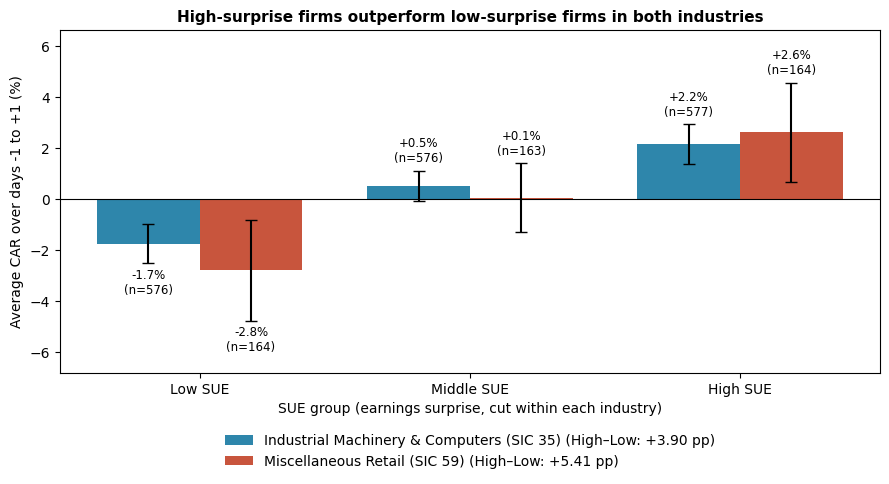

In [24]:
# ===== Figure 1b. Bar chart with percentages on bars and clean finding title =====
d_main = summary.query("industry == @NAME_MAIN and group == 'High'")["mean"].iloc[0] - summary.query("industry == @NAME_MAIN and group == 'Low'")["mean"].iloc[0]
d_comp = summary.query("industry == @NAME_COMP and group == 'High'")["mean"].iloc[0] - summary.query("industry == @NAME_COMP and group == 'Low'")["mean"].iloc[0]
spreads = {NAME_MAIN: d_main, NAME_COMP: d_comp}

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(3)
width = 0.38

for i, name in enumerate([NAME_MAIN, NAME_COMP]):
    sub = summary[summary["industry"] == name].set_index("group").loc[LABELS]
    xpos = x + (i - 0.5) * width
    leg_label = f"{name} (High–Low: {spreads[name]:+.2f} pp)"
    ax.bar(xpos, sub["mean"], width, yerr=sub["ci95"], capsize=4, color=COLORS[name], label=leg_label)

    # Put both average CAR (%) and sample size (n) above positive bars and below negative bars
    for xp, m, ci, n in zip(xpos, sub["mean"], sub["ci95"], sub["count"]):
        if m >= 0:
            ax.annotate(f"{m:+.1f}%\n(n={int(n)})", (xp, m + ci), textcoords="offset points", xytext=(0, 4), ha="center", va="bottom", fontsize=8.5)
        else:
            ax.annotate(f"{m:+.1f}%\n(n={int(n)})", (xp, m - ci), textcoords="offset points", xytext=(0, -4), ha="center", va="top", fontsize=8.5)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels([label + " SUE" for label in LABELS])
ax.set_xlabel("SUE group (earnings surprise, cut within each industry)")
ax.set_ylabel("Average CAR over days -1 to +1 (%)")
ax.set_title("High-surprise firms outperform low-surprise firms in both industries", fontsize=11, fontweight="bold")
ax.margins(y=0.22)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=1, frameon=False)
plt.tight_layout()
fig.savefig("figures/figure1_car_by_sue_group.png", dpi=200, bbox_inches="tight")
plt.show()

In [25]:
# ===== t-test: high SUE group vs low SUE group, for each industry =====
def format_p(p):
    if p < 0.0001:
        return "<0.0001"
    return format(p, ".4f")

ttest_rows = []
for name, df in [(NAME_MAIN, main), (NAME_COMP, comp)]:
    high = df.loc[df["group"] == "High", "car_pct"]
    low  = df.loc[df["group"] == "Low", "car_pct"]
    t_stat, p_value = stats.ttest_ind(high, low, equal_var=False)
    ttest_rows.append({"industry": name,
                       "average CAR high (%)": high.mean(),
                       "average CAR low (%)": low.mean(),
                       "difference high - low (pp)": high.mean() - low.mean(),
                       "t-statistic": t_stat,
                       "p-value": format_p(p_value)})

ttest_table = pd.DataFrame(ttest_rows)
ttest_table.round(4)

,industry,average CAR high (%),average CAR low (%),difference high - low (pp),t-statistic,p-value
0,Industrial Machinery & Computers (SIC 35),2.1561,-1.7407,3.8967,6.9177,<0.0001
1,Miscellaneous Retail (SIC 59),2.6238,-2.7884,5.4122,3.8360,0.0002


In [26]:
# ===== Regressions: (1) simple, (2) year FE, (3) sue*loss, plus 1%/99% winsorized check =====
models = {}
for name, df in [(NAME_MAIN, main), (NAME_COMP, comp)]:
    df = df.dropna(subset=["fyearq"]).copy()
    df["fyearq"] = df["fyearq"].astype(int)          # convert to standard int so C(fyearq) works

    m1 = smf.ols("car_pct ~ sue_pct", data=df).fit()
    m1_win = smf.ols("car_win_pct ~ sue_pct", data=df).fit()
    m2 = smf.ols("car_pct ~ sue_pct + C(fyearq)", data=df).fit()
    m3 = smf.ols("car_pct ~ sue_pct * loss", data=df).fit()
    models[name] = m1                                # save simple model for Figure 2

    table = summary_col([m1, m1_win, m2, m3],
                        stars=True,
                        model_names=["(1) simple", "(1w) winsor 1/99", "(2) year FE", "(3) sue*loss"],
                        info_dict={"N": lambda m: str(int(m.nobs))},
                        regressor_order=["Intercept", "sue_pct", "loss", "sue_pct:loss"],
                        drop_omitted=True,
                        float_format="%.4f")
    print(name)
    print(table)
    print()

Industrial Machinery & Computers (SIC 35)

               (1) simple (1w) winsor 1/99 (2) year FE (3) sue*loss
-------------------------------------------------------------------
Intercept      0.2424     0.2017           0.7323      0.5343**    
               (0.2159)   (0.2028)         (0.9340)    (0.2426)    
sue_pct        0.2164***  0.1893***        0.2190***   0.5225***   
               (0.0409)   (0.0384)         (0.0409)    (0.0741)    
loss                                                   -2.5359***  
                                                       (0.5393)    
sue_pct:loss                                           -0.4780***  
                                                       (0.0887)    
R-squared      0.0159     0.0138           0.0307      0.0449      
R-squared Adj. 0.0154     0.0133           0.0273      0.0432      
N              1729       1729             1729        1729        
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01

Miscellaneous

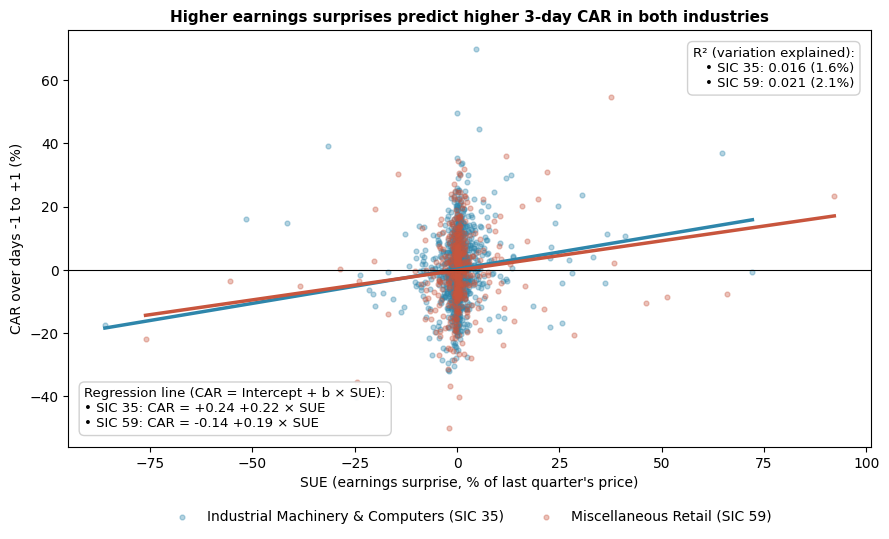

In [27]:
# ===== Figure 2. Scatter plot with R² (top right) and Intercept + Slope (bottom left) =====
fig, ax = plt.subplots(figsize=(9, 5.5))

for name, df in [(NAME_MAIN, main), (NAME_COMP, comp)]:
    ax.scatter(df["sue_pct"], df["car_pct"], s=12, alpha=0.35, color=COLORS[name], label=name)
    a = models[name].params["Intercept"]
    b = models[name].params["sue_pct"]
    x_line = np.linspace(df["sue_pct"].min(), df["sue_pct"].max(), 50)
    ax.plot(x_line, a + b * x_line, color=COLORS[name], linewidth=2.5)

# Top-right corner: R-squared values
r2_box = (
    "R² (variation explained):\n"
    f"• SIC 35: {models[NAME_MAIN].rsquared:.3f} ({models[NAME_MAIN].rsquared:.1%})\n"
    f"• SIC 59: {models[NAME_COMP].rsquared:.3f} ({models[NAME_COMP].rsquared:.1%})"
)
ax.text(0.98, 0.96, r2_box, transform=ax.transAxes, ha="right", va="top", fontsize=9.5,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#CCCCCC", alpha=0.9))

# Bottom-left corner: Intercept and slope coefficient (CAR = a + b * SUE)
eq_box = (
    "Regression line (CAR = Intercept + b × SUE):\n"
    f"• SIC 35: CAR = {models[NAME_MAIN].params['Intercept']:+.2f} {models[NAME_MAIN].params['sue_pct']:+.2f} × SUE\n"
    f"• SIC 59: CAR = {models[NAME_COMP].params['Intercept']:+.2f} {models[NAME_COMP].params['sue_pct']:+.2f} × SUE"
)
ax.text(0.02, 0.04, eq_box, transform=ax.transAxes, ha="left", va="bottom", fontsize=9.5,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="#CCCCCC", alpha=0.9))

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("SUE (earnings surprise, % of last quarter's price)")
ax.set_ylabel("CAR over days -1 to +1 (%)")
ax.set_title("Higher earnings surprises predict higher 3-day CAR in both industries", fontsize=11, fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout()
fig.savefig("figures/figure2_sue_vs_car.png", dpi=200, bbox_inches="tight")
plt.show()

In [28]:
# ===== Figure 3a. The numbers: share of loss quarters, and the slope b with and without loss quarters =====
loss_share = both.groupby("industry")["loss"].mean() * 100

slope_rows = []
for name, df in [(NAME_MAIN, main), (NAME_COMP, comp)]:
    for label, data in [("All quarters", df), ("Profitable quarters only", df[df["loss"] == 0])]:
        model = smf.ols("car_pct ~ sue_pct", data=data).fit()
        low, high = model.conf_int().loc["sue_pct"]
        slope_rows.append({"industry": name, "sample": label, "b": model.params["sue_pct"],
                           "ci_low": low, "ci_high": high, "n": int(model.nobs)})

slopes = pd.DataFrame(slope_rows)
print(loss_share.round(1))
slopes.round(3)

industry
Industrial Machinery & Computers (SIC 35)    19.7
Miscellaneous Retail (SIC 59)                27.3
Name: loss, dtype: float64


,industry,sample,b,ci_low,ci_high,n
0,Industrial Machinery & Computers (SIC 35),All quarters,0.216,0.136,0.297,1729
1,Industrial Machinery & Computers (SIC 35),Profitable quarters only,0.522,0.387,0.658,1388
2,Miscellaneous Retail (SIC 59),All quarters,0.187,0.074,0.300,491
3,Miscellaneous Retail (SIC 59),Profitable quarters only,0.340,0.101,0.579,357


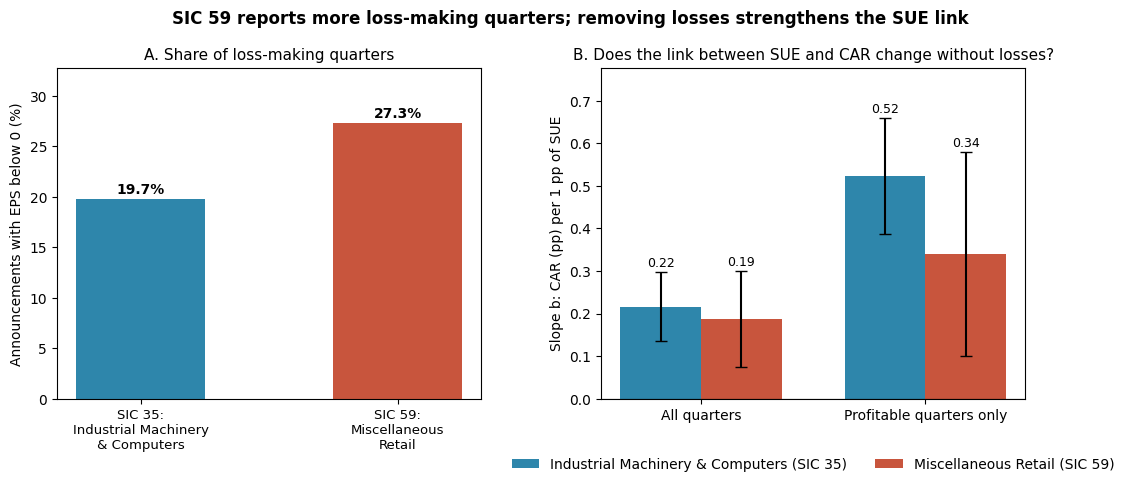

In [29]:
# ===== Figure 3b. Two panels with non-overlapping labels and 1-decimal percentages =====
fig, (axA, axB) = plt.subplots(1, 2, figsize=(11.5, 5))

# Panel A: share of loss-making announcements (1 decimal place: 19.7% vs 27.3%)
short_labels = ["SIC 35:\nIndustrial Machinery\n& Computers", "SIC 59:\nMiscellaneous\nRetail"]
for i, name in enumerate([NAME_MAIN, NAME_COMP]):
    axA.bar(i, loss_share[name], width=0.5, color=COLORS[name])
    axA.annotate(f"{loss_share[name]:.1f}%", (i, loss_share[name]), textcoords="offset points", xytext=(0, 4), ha="center", fontweight="bold")
axA.set_xticks([0, 1])
axA.set_xticklabels(short_labels, fontsize=9.5)
axA.set_ylabel("Announcements with EPS below 0 (%)")
axA.set_ylim(0, max(loss_share) * 1.2)
axA.set_title("A. Share of loss-making quarters", fontsize=11)

# Panel B: slope b (with 95% confidence interval) for all quarters vs profitable quarters only
x = np.arange(2)
width = 0.36
for i, name in enumerate([NAME_MAIN, NAME_COMP]):
    sub = slopes[slopes["industry"] == name].set_index("sample").loc[["All quarters", "Profitable quarters only"]]
    xpos = x + (i - 0.5) * width
    err = [sub["b"] - sub["ci_low"], sub["ci_high"] - sub["b"]]
    axB.bar(xpos, sub["b"], width, yerr=err, capsize=4, color=COLORS[name], label=name)
    for xp, b_val, hi in zip(xpos, sub["b"], sub["ci_high"]):
        axB.annotate(f"{b_val:.2f}", (xp, hi), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)

axB.axhline(0, color="black", linewidth=0.8)
axB.set_xticks(x)
axB.set_xticklabels(["All quarters", "Profitable quarters only"])
axB.set_ylabel("Slope b: CAR (pp) per 1 pp of SUE")
axB.set_ylim(0, slopes["ci_high"].max() * 1.18)
axB.set_title("B. Does the link between SUE and CAR change without losses?", fontsize=11)
axB.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)

fig.suptitle("SIC 59 reports more loss-making quarters; removing losses strengthens the SUE link", fontsize=12, fontweight="bold")
plt.tight_layout()
fig.savefig("figures/figure3_loss_share_and_slope.png", dpi=200, bbox_inches="tight")
plt.show()

In [30]:
# ===== Group averages for the README: no company-level data =====
group_table = summary[["industry", "group", "count", "mean", "ci95"]].rename(columns={"count": "announcements", "mean": "average CAR (%)", "ci95": "95% CI (+/- pp)"})
display(group_table.round(3))

conn.close()

,industry,group,announcements,average CAR (%),95% CI (+/- pp)
0,Industrial Machinery & Computers (SIC 35),Low,576,-1.741,0.771
1,Industrial Machinery & Computers (SIC 35),Middle,576,0.521,0.602
2,Industrial Machinery & Computers (SIC 35),High,577,2.156,0.790
3,Miscellaneous Retail (SIC 59),Low,164,-2.788,1.964
4,Miscellaneous Retail (SIC 59),Middle,163,0.053,1.351
5,Miscellaneous Retail (SIC 59),High,164,2.624,1.947
